# Lab - EDA Univariate Analysis: Amazon UK Product Insights

**Objective:** Explore the distribution, central tendencies and dispersion of Amazon UK product listings to extract actionable business insights.

**Dataset:** Download `amz_uk_price_prediction_dataset.csv` from the [Kaggle source](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction) and place it beside this notebook. The 459 MB source file is intentionally excluded from Git.


## 0. Setup and data loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (10, 6), 'figure.dpi': 110,
                     'axes.titlesize': 14, 'axes.titleweight': 'bold'})
PALETTE = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B3', '#937860']
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

In [2]:
from pathlib import Path

DATA_PATH = Path("amz_uk_price_prediction_dataset.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Download amz_uk_price_prediction_dataset.csv from the Kaggle link in the README "
        "and place it beside this notebook."
    )

df = pd.read_csv(DATA_PATH)
print("Rows x Columns:", df.shape)
df.head()


Rows x Columns: (2443651, 9)


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.70,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.70,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.70,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.70,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.60,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
# Overview: data types, missing values, duplicates
df.info()
print('\nMissing values:')
print(df.isna().sum())
print('\nDuplicate rows:', df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB

Missing values:
uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64



Duplicate rows: 0


### A note on zeros in the `stars` column

In this dataset, products that have not received any rating yet are stored as `stars = 0`. This does **not** mean customers gave them zero stars — it is **missing data**. Because these zeros drag the average down, we exclude them in Part 3.

In [4]:
print('Products with stars = 0:', (df['stars'] == 0).sum())
print('Share of total: {:.1%}'.format((df['stars'] == 0).mean()))

Products with stars = 0: 1225641
Share of total: 50.2%


---
## Part 1: Understanding Product Categories

**Business question:** What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

### 1.1 Frequency table

In [5]:
freq = df['category'].value_counts()
prop = df['category'].value_counts(normalize=True)

freq_table = pd.DataFrame({'count': freq, 'percent': (prop * 100).round(2)})
print('Number of distinct categories:', df['category'].nunique())
freq_table.head(10)

Number of distinct categories: 296


,count,percent
category,,
Sports & Outdoors,836265,34.22
Beauty,19312,0.79
"Handmade Clothing, Shoes & Accessories",19229,0.79
Bath & Body,19092,0.78
Birthday Gifts,18978,0.78
Manicure & Pedicure Products,18940,0.78
Skin Care,18769,0.77
Make-up,18756,0.77
Hair Care,18735,0.77


In [6]:
# Top 5 most listed categories
top5 = freq.head(5)
top5

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

### 1.2 Visualization - Bar chart

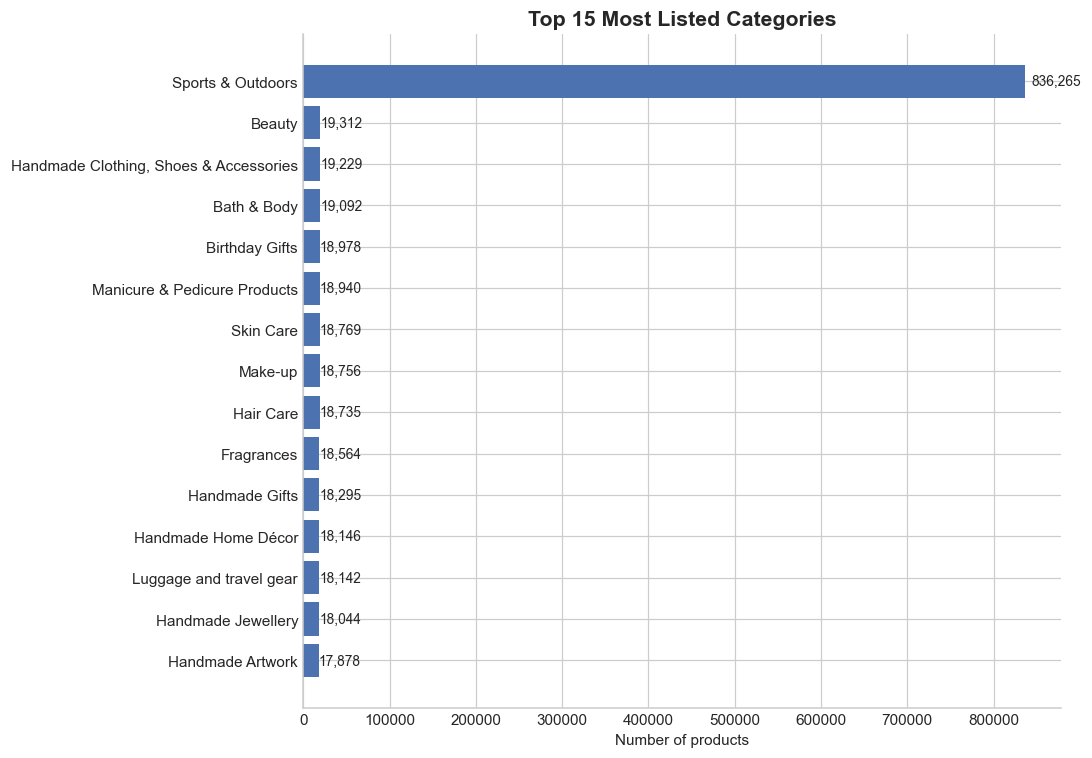

In [7]:
top_n = 15
top_cats = freq.head(top_n).sort_values()

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(top_cats.index, top_cats.values, color=PALETTE[0])
for b in bars:
    ax.text(b.get_width() * 1.01, b.get_y() + b.get_height()/2,
            f'{b.get_width():,.0f}', va='center', fontsize=9)

ax.set_title(f'Top {top_n} Most Listed Categories')
ax.set_xlabel('Number of products')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

**Why not plot every category?** The dataset contains more than 200 categories. Plotting all of them makes the axis labels unreadable, so we focus on the top 15.

### 1.3 Visualization - Pie chart

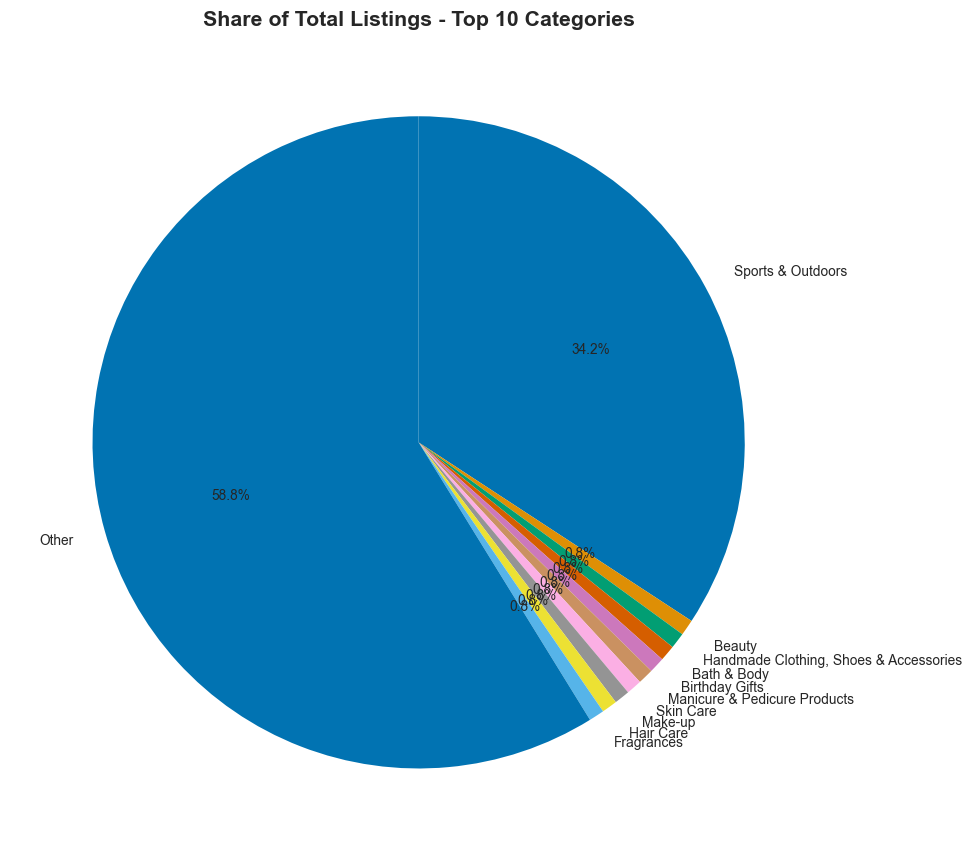

Top 10 categories account for: 41.2%
Largest single category:       34.2%


In [8]:
top10 = freq.head(10)
other = freq.iloc[10:].sum()
pie_data = pd.concat([top10, pd.Series({'Other': other})])

fig, ax = plt.subplots(figsize=(9, 9))
ax.pie(pie_data, labels=pie_data.index, autopct='%1.1f%%',
       startangle=90, counterclock=False,
       colors=sns.color_palette('colorblind', len(pie_data)),
       textprops={'fontsize': 9})
ax.set_title('Share of Total Listings - Top 10 Categories')
plt.tight_layout()
plt.show()

print('Top 10 categories account for: {:.1%}'.format(top10.sum() / len(df)))
print('Largest single category:       {:.1%}'.format(freq.iloc[0] / len(df)))

**Interpretation:** The catalogue is fragmented rather than dominated by one category. The largest categories account for only part of all listings, while many smaller categories form a pronounced long tail. This suggests broad assortment and category-specific competition.


---
## Part 2: Delving into Product Pricing

**Business question:** How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

### 2.1 Measures of centrality

In [9]:
price = df['price'].dropna()

mean_price   = price.mean()
median_price = price.median()
mode_price   = price.mode()[0]

print(f'Mean   : {mean_price:,.2f}')
print(f'Median : {median_price:,.2f}')
print(f'Mode   : {mode_price:,.2f}')

Mean   : 89.24
Median : 19.09
Mode   : 9.99


> **Interpretation:** If the mean is clearly higher than the median, the distribution is **right-skewed** — a small number of very expensive products pull the average up. In that case the median is the better indicator of a "typical" price.

### 2.2 Measures of dispersion

In [10]:
variance = price.var()
std      = price.std()
rng      = price.max() - price.min()
q1, q3   = price.quantile([0.25, 0.75])
iqr      = q3 - q1

print(f'Variance                 : {variance:,.2f}')
print(f'Standard deviation       : {std:,.2f}')
print(f'Range (max - min)        : {rng:,.2f}  (min={price.min():,.2f}, max={price.max():,.2f})')
print(f'Q1 / Q3                  : {q1:,.2f} / {q3:,.2f}')
print(f'IQR                      : {iqr:,.2f}')
print(f'Coefficient of variation : {std/mean_price:.2f}')

Variance                 : 119,445.49
Standard deviation       : 345.61
Range (max - min)        : 100,000.00  (min=0.00, max=100,000.00)
Q1 / Q3                  : 9.99 / 45.99
IQR                      : 36.00
Coefficient of variation : 3.87


In [11]:
# Outlier count using the Tukey 1.5 x IQR rule
lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
outliers = price[(price < lower) | (price > upper)]
print(f'Upper fence   : {upper:,.2f}')
print(f'Outlier count : {len(outliers):,} ({len(outliers)/len(price):.1%})')

Upper fence   : 99.99
Outlier count : 327,688 (13.4%)


### 2.3 Visualization - Histogram

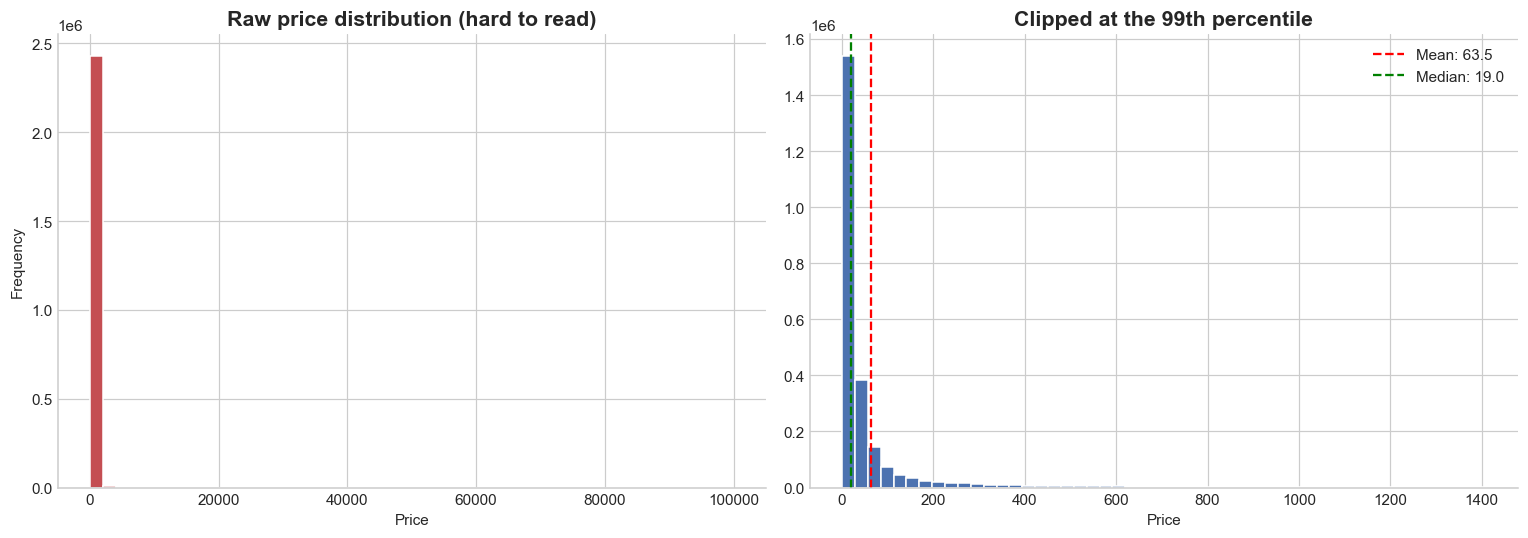

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw data: hard to read
axes[0].hist(price, bins=50, color=PALETTE[3], edgecolor='white')
axes[0].set_title('Raw price distribution (hard to read)')
axes[0].set_xlabel('Price')
axes[0].set_ylabel('Frequency')

# Fix 1: clip at the 99th percentile
clipped = price[price <= price.quantile(0.99)]
axes[1].hist(clipped, bins=50, color=PALETTE[0], edgecolor='white')
axes[1].axvline(clipped.mean(), color='red', ls='--', label=f'Mean: {clipped.mean():,.1f}')
axes[1].axvline(clipped.median(), color='green', ls='--', label=f'Median: {clipped.median():,.1f}')
axes[1].set_title('Clipped at the 99th percentile')
axes[1].set_xlabel('Price')
axes[1].legend()

for a in axes:
    a.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

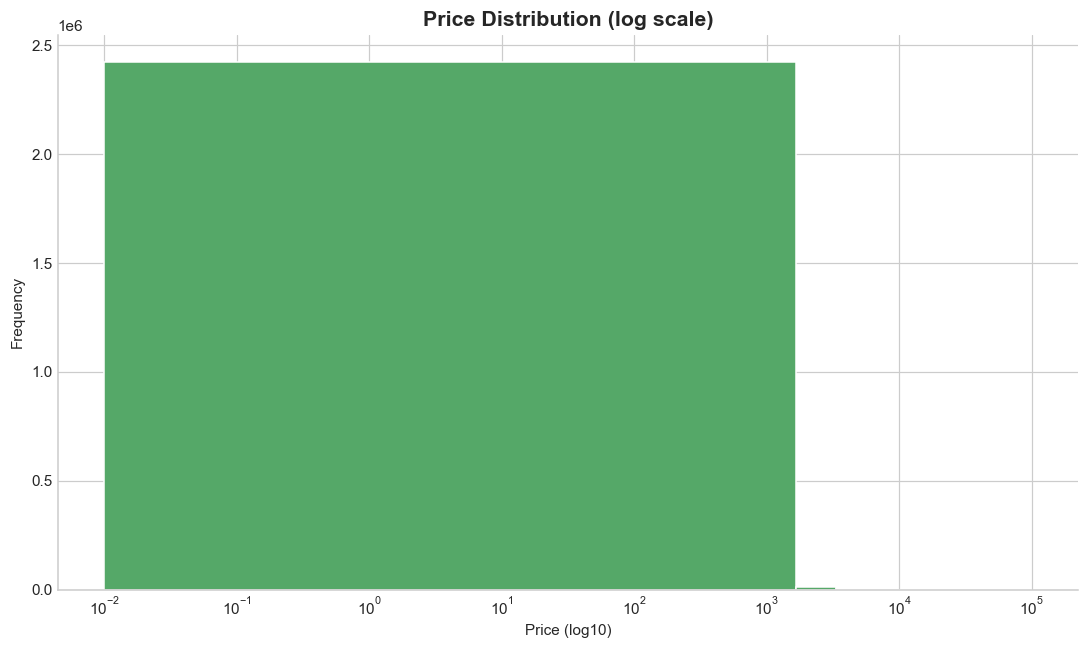

In [13]:
# Fix 2: logarithmic scale
fig, ax = plt.subplots()
ax.hist(price[price > 0], bins=60, color=PALETTE[2], edgecolor='white')
ax.set_xscale('log')
ax.set_title('Price Distribution (log scale)')
ax.set_xlabel('Price (log10)')
ax.set_ylabel('Frequency')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

**Why is the histogram hard to read, and how can it be solved?**

Prices span an extremely wide range and a handful of very expensive products stretch the x-axis. Since matplotlib scales the axis to the maximum value, almost every product gets squeezed into the leftmost bar. Three solutions:

1. **Clipping:** plot only the data up to the 95th or 99th percentile.
2. **Log scale:** `ax.set_xscale('log')` makes skewed distributions legible.
3. **Split the analysis:** examine the main body and the expensive tail separately.

### 2.4 Visualization - Box plot

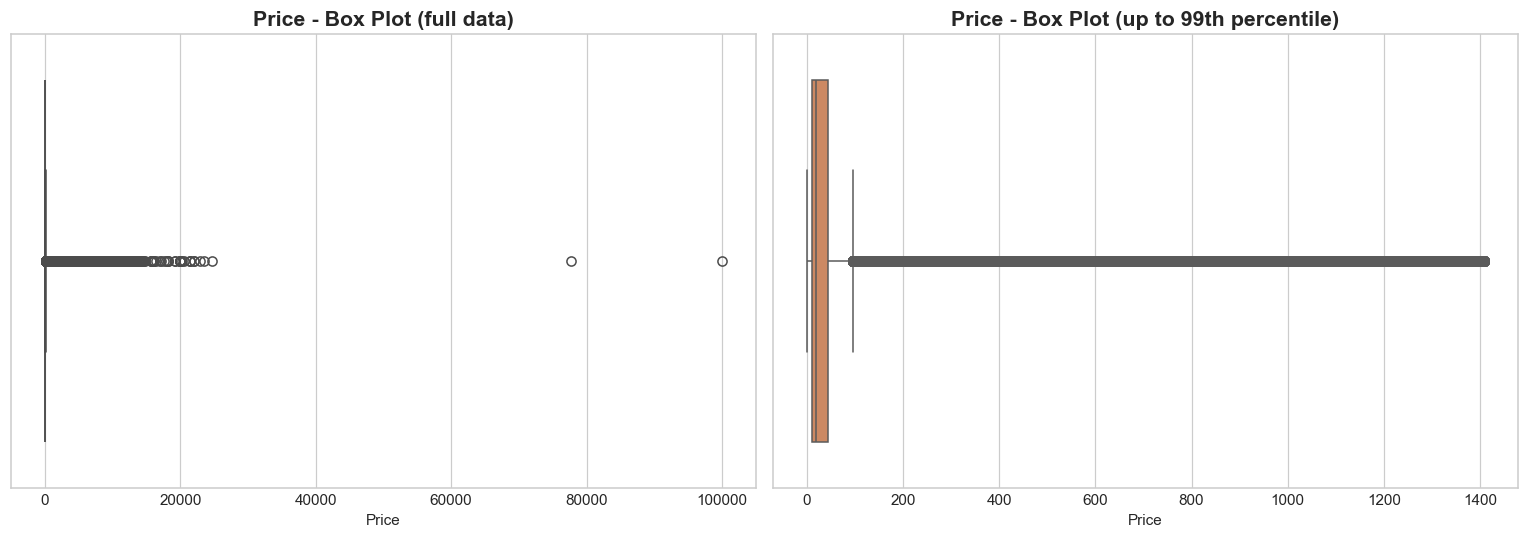

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(x=price, ax=axes[0], color=PALETTE[0])
axes[0].set_title('Price - Box Plot (full data)')
axes[0].set_xlabel('Price')

sns.boxplot(x=clipped, ax=axes[1], color=PALETTE[1])
axes[1].set_title('Price - Box Plot (up to 99th percentile)')
axes[1].set_xlabel('Price')

plt.tight_layout()
plt.show()

In [15]:
# Bonus: top 10 most expensive categories by median price
category_price = (df.groupby('category')['price']
                    .agg(['median', 'mean', 'count'])
                    .query('count >= 100')
                    .sort_values('median', ascending=False))
category_price.head(10)

,median,mean,count
category,,,
Laptops,"1,042.72","1,087.99",7248
Desktop PCs,810.40,926.82,7395
Snowboards,366.73,351.64,640
Home Audio Record Players,326.08,529.67,6374
3D Printers,319.00,"1,018.04",248
Motorbike Exhaust & Exhaust Systems,313.83,366.23,258
Graphics Cards,259.98,444.75,249
Snowboard Boots,258.99,247.96,1449
Lenses,249.99,402.31,3138


---
## Part 3: Unpacking Product Ratings

**Business question:** How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

In [16]:
# Zeros mean "not rated yet" -> excluded from the analysis
ratings = df.loc[df['stars'] > 0, 'stars']
print(f'Products included in the analysis: {len(ratings):,}')

Products included in the analysis: 1,218,010


### 3.1 Measures of centrality

In [17]:
print(f'Mean   : {ratings.mean():.3f}')
print(f'Median : {ratings.median():.3f}')
print(f'Mode   : {ratings.mode()[0]:.3f}')

# For comparison: what the mean would look like with zeros included
print(f'\n[Mean including zeros: {df["stars"].mean():.3f}]  <- misleading')

Mean   : 4.319
Median : 4.400
Mode   : 4.500

[Mean including zeros: 2.153]  <- misleading


### 3.2 Measures of dispersion

In [18]:
q1r, q3r = ratings.quantile([0.25, 0.75])
print(f'Variance           : {ratings.var():.4f}')
print(f'Standard deviation : {ratings.std():.4f}')
print(f'Q1 / Q3            : {q1r:.2f} / {q3r:.2f}')
print(f'IQR                : {q3r - q1r:.2f}')
print(f'Min / Max          : {ratings.min():.1f} / {ratings.max():.1f}')

Variance           : 0.3083
Standard deviation : 0.5553
Q1 / Q3            : 4.10 / 4.60
IQR                : 0.50
Min / Max          : 1.0 / 5.0


### 3.3 Shape of the distribution

In [19]:
skewness = ratings.skew()
kurtosis = ratings.kurt()   # pandas returns excess kurtosis (normal = 0)

print(f'Skewness : {skewness:.3f}')
print(f'Kurtosis : {kurtosis:.3f}')

if skewness < -0.5:
    print('-> Left-skewed: ratings cluster at the high end.')
elif skewness > 0.5:
    print('-> Right-skewed: ratings cluster at the low end.')
else:
    print('-> Approximately symmetric.')

if kurtosis > 0:
    print('-> More peaked than normal, with heavier tails.')
else:
    print('-> Flatter than normal.')

Skewness : -2.380
Kurtosis : 9.782
-> Left-skewed: ratings cluster at the high end.
-> More peaked than normal, with heavier tails.


### 3.4 Visualization - Histogram

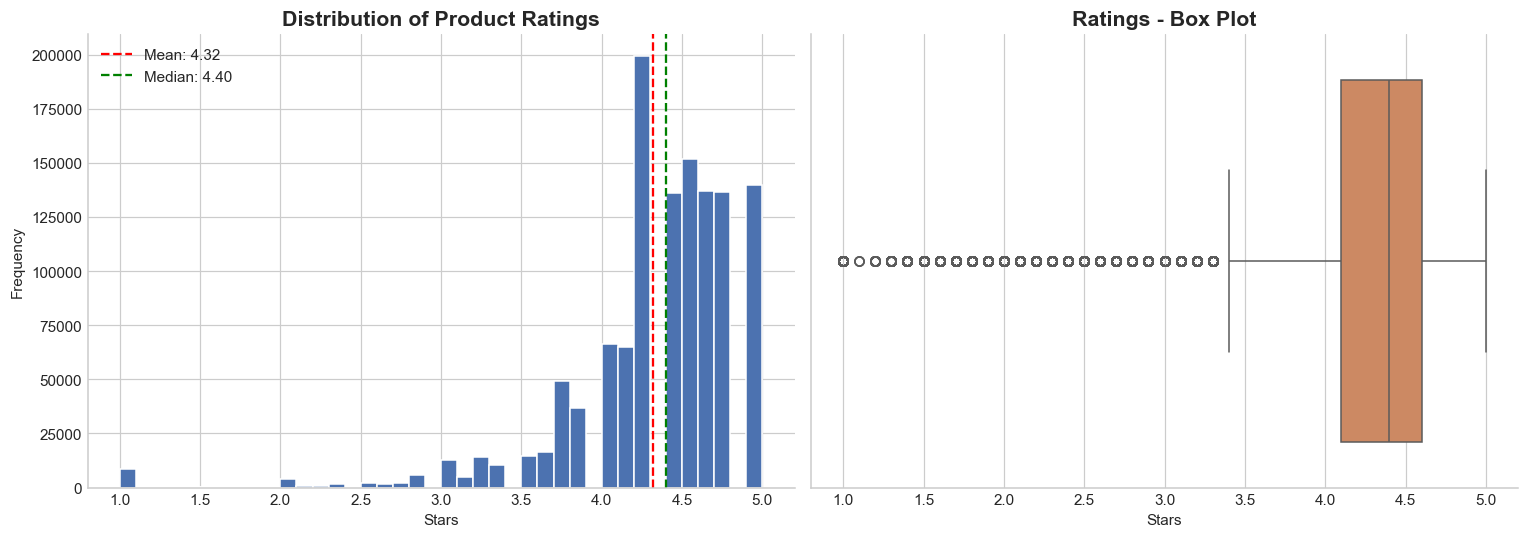

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(ratings, bins=40, color=PALETTE[0], edgecolor='white')
axes[0].axvline(ratings.mean(), color='red', ls='--', label=f'Mean: {ratings.mean():.2f}')
axes[0].axvline(ratings.median(), color='green', ls='--', label=f'Median: {ratings.median():.2f}')
axes[0].set_title('Distribution of Product Ratings')
axes[0].set_xlabel('Stars')
axes[0].set_ylabel('Frequency')
axes[0].legend()

sns.boxplot(x=ratings, ax=axes[1], color=PALETTE[1])
axes[1].set_title('Ratings - Box Plot')
axes[1].set_xlabel('Stars')

for a in axes:
    a.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

In [21]:
# Most common rating values
ratings.round(1).value_counts().head(10).sort_index(ascending=False)

stars
5.00    128492
4.80     41858
4.70     94566
4.60    136995
4.50    151577
4.40    136165
4.30    112564
4.20     86871
4.10     65115
4.00     66089
Name: count, dtype: int64

## Business-Centric Summary Report

The following cell builds the summary directly from the computed results so that the reported values remain synchronized with the dataset.


In [22]:
print("CATEGORY DYNAMICS")
print("Top 5 categories:", ", ".join(freq.head(5).index))
print(f"Top 10 share: {top10.sum() / len(df):.1%}")

print("\nPRICING")
print(f"Mean / median / mode: {mean_price:,.2f} / {median_price:,.2f} / {mode_price:,.2f}")
print(f"Standard deviation / IQR: {std:,.2f} / {iqr:,.2f}")
print(f"Middle 50% price range: {q1:,.2f} to {q3:,.2f}")

print("\nRATINGS")
print(f"Mean / median / mode: {ratings.mean():.3f} / {ratings.median():.3f} / {ratings.mode()[0]:.3f}")
print(f"Skewness / excess kurtosis: {skewness:.3f} / {kurtosis:.3f}")
print(f"Unrated products: {(df['stars'] == 0).mean():.1%}")


CATEGORY DYNAMICS
Top 5 categories: Sports & Outdoors, Beauty, Handmade Clothing, Shoes & Accessories, Bath & Body, Birthday Gifts
Top 10 share: 41.2%

PRICING
Mean / median / mode: 89.24 / 19.09 / 9.99
Standard deviation / IQR: 345.61 / 36.00
Middle 50% price range: 9.99 to 45.99

RATINGS
Mean / median / mode: 4.319 / 4.400 / 4.500
Skewness / excess kurtosis: -2.380 / 9.782
Unrated products: 50.2%
